# 45장 · 질문 전체 일치 검색의 기준선과 빈 결과

검색 기준선은 개선 효과를 비교할 첫 구현입니다. 답변과 출처를 함께 돌려주고, 관련 문서를 놓친 질문도 남깁니다.

질문 한 건을 넣고 검색 결과가 답변과 출처 표시까지 이어지는지 확인합니다. 이 예시는 실제 운영 안내를 흉내 낸 고정 질문과 답으로 연결을 확인합니다. Chroma로 검색한 결과와 모델이 생성한 답변은 별도로 측정합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요.


## retrieve()로 문서 본문·출처 조회

가상 안내 p2가 실린 수업용 페이지판은 1쪽입니다. 문단 ID를 course-guide-v1:p2로 연결하고 본문·출처·쪽수를 함께 넘깁니다. 모의 검색은 Q01의 정확한 문구만 받습니다.


### 셀 01 · retrieve()로 문서 본문·출처 조회

도서관 예제의 library-1 대신 팀 자료의 문서 ID가 보이는지 확인하세요.

기준선 한 행을 만들 때 질문, 기대 문단, 검색이 반환한 원문, 사용자에게 표시할 답을 따로 적으세요. 반환된 원문의 한 구절을 직접 가리킬 수 있는지 확인한 뒤, 화면용으로 짧게 다듬은 문장을 마지막 칸에 씁니다.


In [1]:
submit_doc = {'id': 'course-guide-v1:p2',
 'text': '과제는 학습 관리 페이지의 과제함에 제출합니다. 제출 뒤 파일 이름과 등록 시간을 확인합니다.',
 'source': '가상 과정 운영 안내 · 45일 수업용 페이지판 (source-pages.html)',
 'page': 1}

def retrieve(question, k=2):
    if question.strip() == '과제는 어디에 내나요?':
        return [submit_doc][:k]
    return []

question = '과제는 어디에 내나요?'
found = retrieve(question)
source = found[0]
print(source['text'])
print(source['id'], source['page'])

과제는 학습 관리 페이지의 과제함에 제출합니다. 제출 뒤 파일 이름과 등록 시간을 확인합니다.
course-guide-v1:p2 1


출력은 제출 방법 원문, course-guide-v1:p2, 1입니다. 문단 번호 2를 쪽수에 넣으면 학생이 맞는 쪽으로 갈 수 없습니다. 완성 화면에서는 “과제함에 제출하고 파일 이름과 등록 시간을 확인합니다”라는 가상 답 옆에 이 출처를 표시합니다.


## 관련 문서가 있는데도 검색이 실패하는 경우

Q03은 업로드 실패 시 행동을 묻습니다. p3에 분명한 절차가 있으므로 빈 검색을 올바른 답변 유보로 세면 안 됩니다. 첫 기준선의 알려진 실패로 남겨야 46장의 변경을 비교할 수 있습니다.

<!-- lesson-visual visual-baseline-gap -->
**관련 문서가 있어도 검색 결과가 빌 수 있습니다**

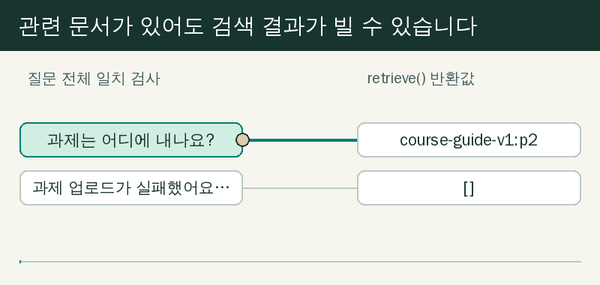

기준선 함수는 공백을 정리한 질문 전체가 지정 문자열과 같을 때만 결과를 줍니다. 업로드 실패 문의는 이 조건에서 탈락합니다.
<!-- /lesson-visual visual-baseline-gap -->


### 셀 02 · 검색 미적중 결과 진단

가상 안내의 업로드 실패 질문을 검색해 보세요.


In [2]:
failure_question = '과제 업로드가 실패했어요. 어떻게 해야 하나요?'
print(retrieve(failure_question))

[]


[]입니다. 검색 규칙이 Q01만 알아보기 때문에 p3까지 가지 못했습니다. 팀이 새로운 원문을 사용한다면 답이 있는 문장, 놓친 질문, 실제 반환 ID를 한 행으로 남기세요.


## 돌아보기

예시 인계 기록은 ‘Q01은 p2에서 답함, Q03은 p3가 있지만 찾지 못함’입니다. 실제 임베딩으로 만든 기준선에는 인덱스 판본과 검색 k도 함께 적습니다.
